# Digital Image Processing Lab – Lab Task 04
## Geometric Transformations with Custom Inputs

| | |
|---|---|
| **Name** | Sheikh Haseeb-ur-Rehman |
| **Roll No** | 2024-SE-31 |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Semester / Session** | Fifth / 2024-28 (SE) |
| **Department** | Software Engineering, The University of Azad Jammu and Kashmir |

**Objective:** build one reusable `transform` function that accepts an image, an operation name and that
operation's custom parameters, validates everything, and returns a correctly transformed image.

**Contents**
1. Setup and declared limits
2. Loading and validating the image (original kept unchanged)
3. The reusable `transform` function and its validation
4. Prompt-driven input (recorded session and live controls)
5. Demonstration of every operation with custom values (labelled and saved), including the affine matrices
6. Interpolation comparison on an enlarged patch
7. Rejected inputs (at least one per operation)
8. Identity checks (expected vs actual, Pass/Fail)
9. Observations: coordinates vs indexing, aspect ratio, canvas expansion, clipping
10. Final integrity check

## 1. Setup and declared limits

In [1]:
import os
import math
import hashlib
import numbers
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")            # keeps the saved notebook small
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

# ---- paths -------------------------------------------------------------
IMAGE_PATH  = "input_image.jpg"   # input image lives next to this notebook
RESULTS_DIR = "results"           # every transformed result is saved here
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- declared limits and fixed choices (enforced inside `transform`) ----
MAX_SIDE   = 10_000        # maximum output width or height, in pixels
MAX_PIXELS = 25_000_000    # maximum output width * height (25 megapixels)
FILL_VALUE = (0, 0, 0)     # background for areas exposed by translation / rotation (black)

SUPPORTED_OPERATIONS = ("scale", "crop", "flip", "translate", "rotate")

INTERPOLATIONS = {          # user-facing name -> OpenCV flag
    "nearest":  cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic":  cv2.INTER_CUBIC,
    "lanczos":  cv2.INTER_LANCZOS4,
}
FLIP_DIRECTIONS = ("horizontal", "vertical", "both")
ROTATION_INTERPOLATION = cv2.INTER_LINEAR   # rotation / translation resampling (bilinear)

REQUIRED_PARAMS = {         # exactly these keyword parameters are required, no hidden defaults
    "scale":     ("fx", "fy", "interpolation"),
    "crop":      ("left", "top", "right", "bottom"),
    "flip":      ("direction",),
    "translate": ("tx", "ty"),
    "rotate":    ("angle", "expand"),
}

print(f"Max output size : {MAX_SIDE} px per side and {MAX_PIXELS:,} pixels in total")
print(f"Fill colour     : {FILL_VALUE} (black) for exposed background")

OpenCV : 5.0.0
NumPy  : 2.5.4
Max output size : 10000 px per side and 25,000,000 pixels in total
Fill colour     : (0, 0, 0) (black) for exposed background


## 2. Loading and validating the image

`load_image` checks that the file **exists**, **decodes successfully** and has **non-zero dimensions**.
Colour handling is consistent across the whole notebook: OpenCV decodes to **BGR**, so the image is converted to
**RGB once, at load time**. All processing and Matplotlib display use RGB, and the image is converted back to BGR only
when writing a file with `cv2.imwrite` (see `save_image`).

In [2]:
class ImageLoadError(Exception):
    '''Raised when the input image cannot be loaded or is unusable.'''


def load_image(path):
    '''Load an image as an RGB uint8 array, validating file, decoding and size.'''
    if not isinstance(path, (str, os.PathLike)):
        raise ImageLoadError(f"Path must be a string, got {type(path).__name__}.")
    if not os.path.isfile(path):
        raise ImageLoadError(f"File does not exist: '{path}'.")
    if os.path.getsize(path) == 0:
        raise ImageLoadError(f"File is empty (0 bytes): '{path}'.")
    bgr = cv2.imread(os.fspath(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ImageLoadError(f"File exists but could not be decoded as an image: '{path}'.")
    if bgr.ndim != 3 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise ImageLoadError(f"Decoded image has invalid dimensions: {bgr.shape}.")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)          # BGR -> RGB (done once, here)


def save_image(path, rgb):
    '''Save an RGB array to disk (converted back to BGR for OpenCV).'''
    params = [cv2.IMWRITE_JPEG_QUALITY, 95] if path.lower().endswith((".jpg", ".jpeg")) else []
    ok = cv2.imwrite(path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), params)
    if not ok:
        raise IOError(f"Could not write '{path}'.")
    return path


# ---- demonstrate the loader on bad inputs first -------------------------
with open("not_an_image.jpg", "w") as f:                  # a file that exists but is not an image
    f.write("this is plain text, not a JPEG")

for bad in ["does_not_exist.jpg", "not_an_image.jpg"]:
    try:
        load_image(bad)
        print(f"{bad!r}: loaded (unexpected)")
    except ImageLoadError as e:
        print(f"REJECTED {bad!r:24} -> {e}")
os.remove("not_an_image.jpg")                             # clean up the temporary file

# ---- load the real image -------------------------------------------------
original = load_image(IMAGE_PATH)
original.flags.writeable = False                          # the original can no longer be modified
ORIGINAL_HASH = hashlib.sha256(original.tobytes()).hexdigest()

H0, W0 = original.shape[:2]
print(f"\nLoaded '{IMAGE_PATH}' successfully")
print(f"Width  : {W0} px")
print(f"Height : {H0} px")
print(f"Array shape (rows, cols, channels) : {original.shape}   dtype={original.dtype}")
print(f"Colour order : RGB (converted once from OpenCV's BGR)")
print(f"SHA-256 of original (checked again at the end): {ORIGINAL_HASH[:16]}...")

REJECTED 'does_not_exist.jpg'     -> File does not exist: 'does_not_exist.jpg'.
REJECTED 'not_an_image.jpg'       -> File exists but could not be decoded as an image: 'not_an_image.jpg'.

Loaded 'input_image.jpg' successfully
Width  : 2400 px
Height : 1792 px
Array shape (rows, cols, channels) : (1792, 2400, 3)   dtype=uint8
Colour order : RGB (converted once from OpenCV's BGR)
SHA-256 of original (checked again at the end): e7357b1ae7f29cd9...


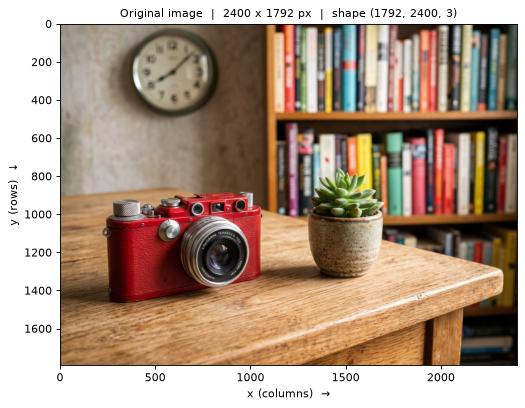

In [3]:
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.imshow(original)
ax.set_title(f"Original image  |  {W0} x {H0} px  |  shape {original.shape}", fontsize=10)
ax.set_xlabel("x (columns)  →"); ax.set_ylabel("y (rows)  ↓")
plt.tight_layout(); plt.show()

## 3. The reusable `transform` function

`transform(image, operation, **params)` is the **single entry point**. The operation name selects the behaviour and the
keyword arguments carry the custom values; nothing is hard-coded inside it. It validates the image, the operation
name and every parameter itself, and raises `ValidationError` with a clear message rather than guessing or silently
substituting defaults.

| Operation | Required keyword parameters | Rules enforced |
|---|---|---|
| `scale` | `fx`, `fy`, `interpolation` | finite and > 0; output size = `round(w*fx)`, `round(h*fy)` ≥ 1 px; interpolation ∈ nearest, bilinear, bicubic, lanczos; max output size |
| `crop` | `left`, `top`, `right`, `bottom` | integers; `0 ≤ left < right ≤ width`, `0 ≤ top < bottom ≤ height` (right/bottom exclusive) |
| `flip` | `direction` | one of `horizontal`, `vertical`, `both` |
| `translate` | `tx`, `ty` | finite numbers (positive, negative or zero); canvas size unchanged |
| `rotate` | `angle`, `expand` | angle finite (any value incl. 0 and negative); `expand` is a real bool |

In [4]:
class ValidationError(ValueError):
    '''Raised for any invalid image, operation name or parameter.'''


# ------------------------------ validators --------------------------------
def _validate_image(image):
    if not isinstance(image, np.ndarray):
        raise ValidationError(f"image must be a NumPy array, got {type(image).__name__}.")
    if image.dtype != np.uint8:
        raise ValidationError(f"image dtype must be uint8, got {image.dtype}.")
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] != 3):
        raise ValidationError(f"image must have shape (H, W) or (H, W, 3), got {image.shape}.")
    if image.shape[0] == 0 or image.shape[1] == 0:
        raise ValidationError(f"image has zero size: {image.shape}.")


def _number(name, value):
    '''Return `value` as a finite float. Rejects bool, text, None, NaN and +/- infinity.'''
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Real):
        raise ValidationError(f"'{name}' must be a number, got {value!r} ({type(value).__name__}).")
    value = float(value)
    if not math.isfinite(value):
        raise ValidationError(f"'{name}' must be finite (not NaN or infinity), got {value}.")
    return value


def _integer(name, value):
    '''Return `value` as int. Only true integers are accepted (10.5 and "10" are rejected).'''
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Integral):
        raise ValidationError(f"'{name}' must be an integer, got {value!r} ({type(value).__name__}).")
    return int(value)


def _check_output_size(w, h):
    '''Reject empty or oversize outputs. Raises before any large array is allocated.'''
    if w < 1 or h < 1:
        raise ValidationError(f"output would be {w} x {h} px; both dimensions must be at least 1 pixel.")
    if w > MAX_SIDE or h > MAX_SIDE:
        raise ValidationError(f"output {w} x {h} px exceeds the maximum side length of {MAX_SIDE} px.")
    if w * h > MAX_PIXELS:
        raise ValidationError(f"output {w} x {h} = {w*h:,} px exceeds the maximum of {MAX_PIXELS:,} pixels.")


def _check_params(operation, params):
    required = REQUIRED_PARAMS[operation]
    missing = [p for p in required if p not in params]
    if missing:
        raise ValidationError(f"'{operation}' is missing required parameter(s): {', '.join(missing)}.")
    unexpected = [p for p in params if p not in required]
    if unexpected:
        raise ValidationError(f"'{operation}' got unexpected parameter(s): {', '.join(unexpected)}. "
                              f"Allowed: {', '.join(required)}.")


# ------------------------- affine matrices (2 x 3) -------------------------
def translation_matrix(tx, ty):
    '''2x3 affine matrix of a shift:  x' = x + tx,  y' = y + ty.'''
    return np.float64([[1, 0, tx], [0, 1, ty]])


def rotation_matrix(w, h, angle, expand):
    '''
    2x3 affine matrix that rotates about the image centre, plus the output size (ow, oh).
    Positive angle = counter-clockwise as displayed (OpenCV convention, y axis points down).
    With expand=True the canvas grows to the bounding box and the matrix is shifted to fit it.
    '''
    angle = math.fmod(angle, 360.0)                  # same rotation, better numeric precision for huge angles
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0            # image centre (pixel-centre convention)
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    ow, oh = w, h
    if expand:
        rad = math.radians(angle)
        c, s = abs(math.cos(rad)), abs(math.sin(rad))
        ow = int(math.ceil(round(w * c + h * s, 6)))  # round() guards against 1e-13 noise at 90 degrees
        oh = int(math.ceil(round(w * s + h * c, 6)))
        _check_output_size(ow, oh)
        M[0, 2] += (ow - 1) / 2.0 - cx               # move the old centre to the new canvas centre
        M[1, 2] += (oh - 1) / 2.0 - cy
    return M, ow, oh


# ------------------------------ operations --------------------------------
def _scale(image, fx, fy, interpolation):
    fx, fy = _number("fx", fx), _number("fy", fy)
    if fx <= 0 or fy <= 0:
        raise ValidationError(f"scale factors must be greater than zero, got fx={fx}, fy={fy}.")
    if not isinstance(interpolation, str) or interpolation.strip().lower() not in INTERPOLATIONS:
        raise ValidationError(f"unsupported interpolation {interpolation!r}. "
                              f"Choose one of: {', '.join(INTERPOLATIONS)}.")
    h, w = image.shape[:2]
    ow_f, oh_f = w * fx, h * fy                      # float output size (can overflow to inf for huge factors)
    if not (math.isfinite(ow_f) and math.isfinite(oh_f)):
        raise ValidationError("scale factors are too large: output size is not representable.")
    ow, oh = int(round(ow_f)), int(round(oh_f))
    _check_output_size(ow, oh)
    return cv2.resize(image, (ow, oh), interpolation=INTERPOLATIONS[interpolation.strip().lower()])


def _crop(image, left, top, right, bottom):
    left, top = _integer("left", left), _integer("top", top)
    right, bottom = _integer("right", right), _integer("bottom", bottom)
    h, w = image.shape[:2]
    if not (0 <= left < right <= w):
        raise ValidationError(f"horizontal crop must satisfy 0 <= left < right <= {w}; "
                              f"got left={left}, right={right}.")
    if not (0 <= top < bottom <= h):
        raise ValidationError(f"vertical crop must satisfy 0 <= top < bottom <= {h}; "
                              f"got top={top}, bottom={bottom}.")
    return image[top:bottom, left:right].copy()      # right and bottom are exclusive


def _flip(image, direction):
    if not isinstance(direction, str) or direction.strip().lower() not in FLIP_DIRECTIONS:
        raise ValidationError(f"unsupported flip direction {direction!r}. "
                              f"Choose one of: {', '.join(FLIP_DIRECTIONS)}.")
    d = direction.strip().lower()
    code_ = {"horizontal": 1, "vertical": 0, "both": -1}[d]
    return cv2.flip(image, code_)


def _translate(image, tx, ty):
    tx, ty = _number("tx", tx), _number("ty", ty)
    h, w = image.shape[:2]
    fill = FILL_VALUE if image.ndim == 3 else FILL_VALUE[0]
    if abs(tx) >= w or abs(ty) >= h:                 # shifted completely off the canvas
        out = np.empty_like(image)
        out[...] = fill
        return out
    M = translation_matrix(tx, ty)                   # x' = x + tx, y' = y + ty
    return cv2.warpAffine(image, M, (w, h), flags=ROTATION_INTERPOLATION,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=fill)


def _rotate(image, angle, expand):
    angle = _number("angle", angle)
    if not isinstance(expand, (bool, np.bool_)):
        raise ValidationError(f"'expand' must be True or False, got {expand!r} ({type(expand).__name__}).")
    h, w = image.shape[:2]
    fill = FILL_VALUE if image.ndim == 3 else FILL_VALUE[0]
    M, ow, oh = rotation_matrix(w, h, angle, expand)
    return cv2.warpAffine(image, M, (ow, oh), flags=ROTATION_INTERPOLATION,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=fill)


_DISPATCH = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}


# ------------------------------ entry point --------------------------------
def transform(image, operation, **params):
    '''
    Single entry point for all geometric transformations.

    image     : uint8 RGB array (H, W, 3) (or grayscale (H, W)); never modified.
    operation : 'scale' | 'crop' | 'flip' | 'translate' | 'rotate'
    **params  : the operation's custom parameters (see REQUIRED_PARAMS).

    Returns a NEW image array. Raises ValidationError for any invalid input.
    '''
    _validate_image(image)
    if not isinstance(operation, str):
        raise ValidationError(f"operation must be a string, got {type(operation).__name__}.")
    op = operation.strip().lower()
    if op not in SUPPORTED_OPERATIONS:
        raise ValidationError(f"unknown operation {operation!r}. Supported: {', '.join(SUPPORTED_OPERATIONS)}.")
    _check_params(op, params)
    return _DISPATCH[op](image, **params)


print("transform() defined. Supported operations:", ", ".join(SUPPORTED_OPERATIONS))
print("Positive rotation angles turn the image COUNTER-CLOCKWISE (as displayed); negative angles turn it clockwise.")

transform() defined. Supported operations: scale, crop, flip, translate, rotate
Positive rotation angles turn the image COUNTER-CLOCKWISE (as displayed); negative angles turn it clockwise.


### 3.1 Display and save helpers

`show_comparison` draws the original beside the result. The result's title carries the **operation, parameters and
output dimensions**; both panels use real pixel axes so size changes are visible. `run` calls `transform`, shows the
comparison and saves the result into `results/`.

In [5]:
def fmt_params(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())


def show_comparison(original, result, operation, params, title_prefix=""):
    '''Original vs transformed with labels: operation, parameters, output dimensions.'''
    oh, ow = original.shape[:2]
    rh, rw = result.shape[:2]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    axes[0].imshow(original)
    axes[0].set_title(f"ORIGINAL\n{ow} x {oh} px", fontsize=9)
    axes[1].imshow(result)
    axes[1].set_title(f"{title_prefix}{operation.upper()}  ({fmt_params(params)})\n"
                      f"output {rw} x {rh} px", fontsize=9)
    for ax in axes:
        ax.tick_params(labelsize=7)
        ax.set_xlabel("x (px)", fontsize=7); ax.set_ylabel("y (px)", fontsize=7)
    plt.tight_layout(); plt.show()


def run(image, operation, filename, title_prefix="", **params):
    '''transform -> labelled comparison -> save. Returns the transformed image.'''
    result = transform(image, operation, **params)
    path = save_image(os.path.join(RESULTS_DIR, filename), result)
    show_comparison(image, result, operation, params, title_prefix)
    print(f"{operation:9} {fmt_params(params):55} -> output {result.shape[1]} x {result.shape[0]} px  | saved: {path}")
    return result

## 4. Prompt-driven input

The user **selects an operation and types its parameters**; the values are parsed, then **passed to `transform`**
(nothing is fixed inside it). The prompt layer validates the typed text (non-numeric text, NaN, infinity, wrong
choices) and shows a clear message, then asks again. If `transform` rejects a combination (for example
`right <= left` in a crop) the message is shown and the parameters for that operation can be re-entered. Typing `q`
at any prompt cancels.

**How to use it live:** set `LIVE_INPUT = True` in the cell below and run `interactive_session(original, input)`.
The **recorded run** in this notebook feeds a fixed list of "typed" answers (including mistakes) through the very same
prompts, so the notebook runs end-to-end without waiting for the keyboard. Each answer is echoed after its prompt.

For typing your own values interactively with controls, use the live panel in section 4.2.


In [6]:
class Cancelled(Exception):
    '''Raised when the user types q at a prompt.'''


# ------------------------- text parsers (typed text -> value) -------------------------
def parse_float(name, text, positive=False):
    text = text.strip()
    try:
        value = float(text)
    except ValueError:
        raise ValidationError(f"'{text}' is not a number. Enter a value such as 1.5, -20 or 0.")
    value = _number(name, value)                                   # rejects NaN / inf
    if positive and value <= 0:
        raise ValidationError(f"'{name}' must be greater than zero, got {value}.")
    return value


def parse_int(name, text):
    text = text.strip()
    try:
        return int(text)
    except ValueError:
        raise ValidationError(f"'{text}' is not a whole number. Enter an integer such as 0 or 250.")


def parse_choice(name, text, choices):
    text = text.strip().lower()
    if text not in choices:
        raise ValidationError(f"'{text}' is not supported. Choose one of: {', '.join(choices)}.")
    return text


def parse_bool(name, text):
    t = text.strip().lower()
    if t in ("y", "yes", "true", "1"):
        return True
    if t in ("n", "no", "false", "0"):
        return False
    raise ValidationError(f"'{text}' is not a valid choice. Enter y or n.")


# what to ask for each operation: (parameter name, prompt text, parser)
PROMPTS = {
    "scale": [("fx", "Horizontal scale factor fx (> 0)", lambda t: parse_float("fx", t, positive=True)),
              ("fy", "Vertical scale factor fy (> 0)",   lambda t: parse_float("fy", t, positive=True)),
              ("interpolation", f"Interpolation ({'/'.join(INTERPOLATIONS)})",
               lambda t: parse_choice("interpolation", t, tuple(INTERPOLATIONS)))],
    "crop": [("left",   "Left   x (integer, inclusive)",  lambda t: parse_int("left", t)),
             ("top",    "Top    y (integer, inclusive)",  lambda t: parse_int("top", t)),
             ("right",  "Right  x (integer, exclusive)",  lambda t: parse_int("right", t)),
             ("bottom", "Bottom y (integer, exclusive)",  lambda t: parse_int("bottom", t))],
    "flip": [("direction", f"Direction ({'/'.join(FLIP_DIRECTIONS)})",
              lambda t: parse_choice("direction", t, FLIP_DIRECTIONS))],
    "translate": [("tx", "Horizontal offset tx in px (+ right, - left)", lambda t: parse_float("tx", t)),
                  ("ty", "Vertical offset ty in px (+ down, - up)",      lambda t: parse_float("ty", t))],
    "rotate": [("angle", "Angle in degrees (+ counter-clockwise, - clockwise)", lambda t: parse_float("angle", t)),
               ("expand", "Expand canvas to fit the whole rotated image? (y/n)", lambda t: parse_bool("expand", t))],
}


class ScriptedInput:
    '''Feeds pre-written answers through the normal prompts and echoes them, like a typed session.'''
    def __init__(self, answers):
        self._answers = iter(answers)

    def __call__(self, prompt=""):
        try:
            answer = next(self._answers)
        except StopIteration:
            raise Cancelled("scripted input exhausted")
        print(f"{prompt}{answer}")
        return answer


def ask(prompt, parser, input_fn):
    '''Ask until the typed text parses; show a clear message on each mistake.'''
    while True:
        text = input_fn(f"  {prompt}: ")
        if text.strip().lower() == "q":
            raise Cancelled()
        try:
            return parser(text)
        except ValidationError as e:
            print(f"    ✗ Invalid input: {e}  -> please try again.")


def prompt_for_transform(image, input_fn=input):
    '''Select an operation, collect its parameters, call transform. Returns (operation, params, result).'''
    ops = ", ".join(SUPPORTED_OPERATIONS)
    operation = ask(f"Operation ({ops})", lambda t: parse_choice("operation", t, SUPPORTED_OPERATIONS), input_fn)
    while True:
        params = {name: ask(text, parser, input_fn) for name, text, parser in PROMPTS[operation]}
        try:
            return operation, params, transform(image, operation, **params)   # values passed to transform
        except ValidationError as e:
            print(f"    ✗ transform rejected these values: {e}\n      -> please re-enter the {operation} parameters.")


def interactive_session(image, input_fn=input, save_prefix="interactive"):
    '''Repeat: choose operation, enter parameters, view and save the result. Stops on q or when asked.'''
    count = 0
    while True:
        print("\n--- New transformation (type q to quit) ---")
        try:
            operation, params, result = prompt_for_transform(image, input_fn)
        except Cancelled:
            print("Session ended.")
            return
        count += 1
        name = f"{save_prefix}_{count:02d}_{operation}.jpg"
        save_image(os.path.join(RESULTS_DIR, name), result)
        show_comparison(image, result, operation, params)
        print(f"  ✓ {operation}({fmt_params(params)}) -> {result.shape[1]} x {result.shape[0]} px, saved results/{name}")
        again = ask("Another transformation? (y/n)", lambda t: parse_bool("again", t), input_fn)
        if not again:
            print("Session ended.")
            return


LIVE_INPUT = False      # set True to type your own values (uses the notebook's input() box)
print("Prompt layer ready.  LIVE_INPUT =", LIVE_INPUT)

Prompt layer ready.  LIVE_INPUT = False


### 4.1 Recorded interactive session

The scripted answers below deliberately include **mistakes** (unknown operation, non-numeric text, `nan`, `inf`,
zero or negative scale factor, unsupported choices, non-integer crop value, a crop with `right <= left`) so you can see
the error messages and the correction loop. Every operation is then run once with valid custom values.


--- New transformation (type q to quit) ---
  Operation (scale, crop, flip, translate, rotate): blur
    ✗ Invalid input: 'blur' is not supported. Choose one of: scale, crop, flip, translate, rotate.  -> please try again.
  Operation (scale, crop, flip, translate, rotate): scale
  Horizontal scale factor fx (> 0): abc
    ✗ Invalid input: 'abc' is not a number. Enter a value such as 1.5, -20 or 0.  -> please try again.
  Horizontal scale factor fx (> 0): 0
    ✗ Invalid input: 'fx' must be greater than zero, got 0.0.  -> please try again.
  Horizontal scale factor fx (> 0): 1.5
  Vertical scale factor fy (> 0): inf
    ✗ Invalid input: 'fy' must be finite (not NaN or infinity), got inf.  -> please try again.
  Vertical scale factor fy (> 0): 0.75
  Interpolation (nearest/bilinear/bicubic/lanczos): sharpest
    ✗ Invalid input: 'sharpest' is not supported. Choose one of: nearest, bilinear, bicubic, lanczos.  -> please try again.
  Interpolation (nearest/bilinear/bicubic/lanczos): lancz

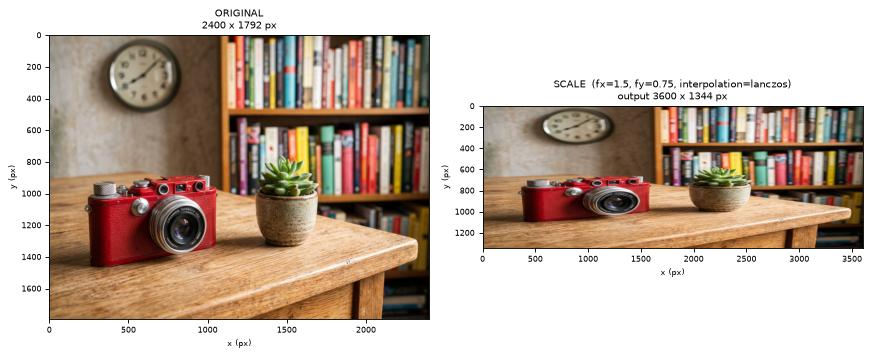

  ✓ scale(fx=1.5, fy=0.75, interpolation=lanczos) -> 3600 x 1344 px, saved results/interactive_01_scale.jpg
  Another transformation? (y/n): y

--- New transformation (type q to quit) ---
  Operation (scale, crop, flip, translate, rotate): crop
  Left   x (integer, inclusive): 100.5
    ✗ Invalid input: '100.5' is not a whole number. Enter an integer such as 0 or 250.  -> please try again.
  Left   x (integer, inclusive): 800
  Top    y (integer, inclusive): 300
  Right  x (integer, exclusive): 600
  Bottom y (integer, exclusive): 1300
    ✗ transform rejected these values: horizontal crop must satisfy 0 <= left < right <= 2400; got left=800, right=600.
      -> please re-enter the crop parameters.
  Left   x (integer, inclusive): 800
  Top    y (integer, inclusive): 300
  Right  x (integer, exclusive): 1700
  Bottom y (integer, exclusive): 1300


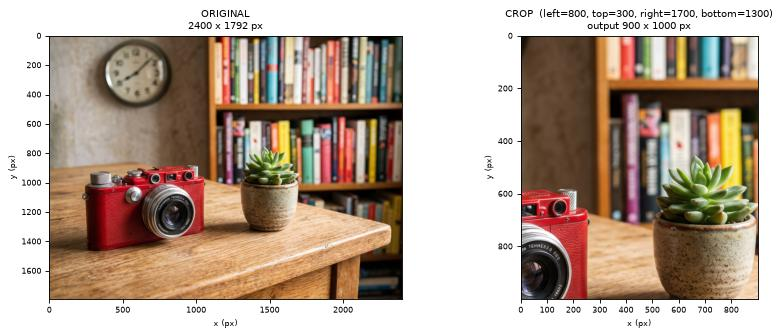

  ✓ crop(left=800, top=300, right=1700, bottom=1300) -> 900 x 1000 px, saved results/interactive_02_crop.jpg
  Another transformation? (y/n): y

--- New transformation (type q to quit) ---
  Operation (scale, crop, flip, translate, rotate): flip
  Direction (horizontal/vertical/both): diagonal
    ✗ Invalid input: 'diagonal' is not supported. Choose one of: horizontal, vertical, both.  -> please try again.
  Direction (horizontal/vertical/both): both


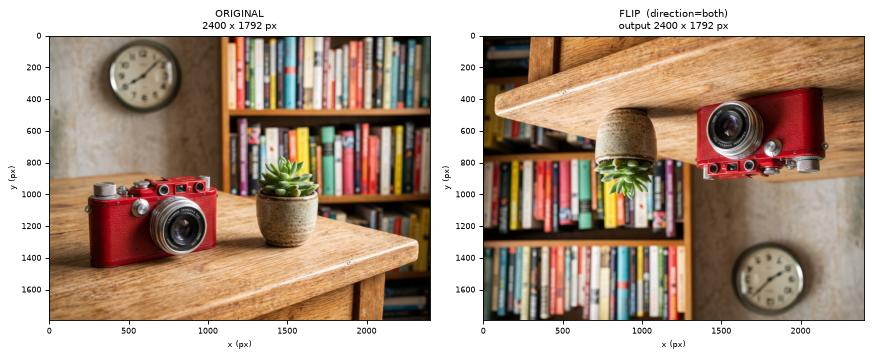

  ✓ flip(direction=both) -> 2400 x 1792 px, saved results/interactive_03_flip.jpg
  Another transformation? (y/n): y

--- New transformation (type q to quit) ---
  Operation (scale, crop, flip, translate, rotate): translate
  Horizontal offset tx in px (+ right, - left): nan
    ✗ Invalid input: 'tx' must be finite (not NaN or infinity), got nan.  -> please try again.
  Horizontal offset tx in px (+ right, - left): -400
  Vertical offset ty in px (+ down, - up): 250


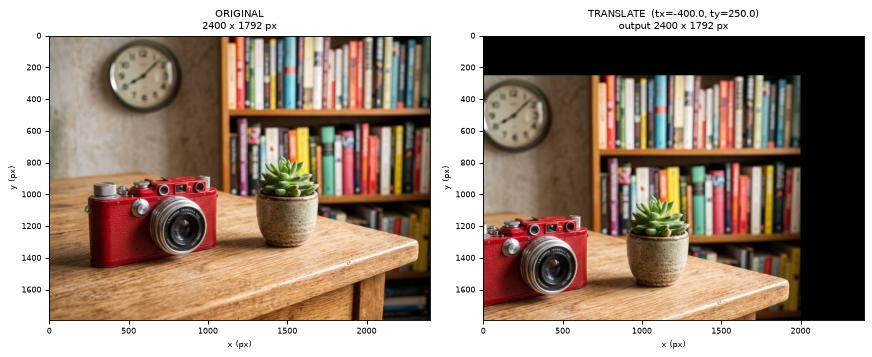

  ✓ translate(tx=-400.0, ty=250.0) -> 2400 x 1792 px, saved results/interactive_04_translate.jpg
  Another transformation? (y/n): y

--- New transformation (type q to quit) ---
  Operation (scale, crop, flip, translate, rotate): rotate
  Angle in degrees (+ counter-clockwise, - clockwise): ninety
    ✗ Invalid input: 'ninety' is not a number. Enter a value such as 1.5, -20 or 0.  -> please try again.
  Angle in degrees (+ counter-clockwise, - clockwise): -35
  Expand canvas to fit the whole rotated image? (y/n): maybe
    ✗ Invalid input: 'maybe' is not a valid choice. Enter y or n.  -> please try again.
  Expand canvas to fit the whole rotated image? (y/n): y


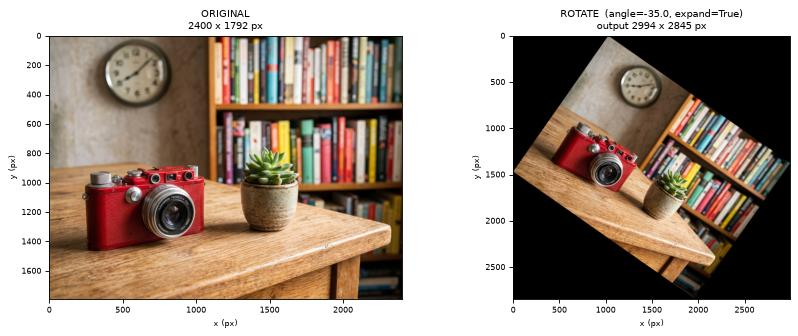

  ✓ rotate(angle=-35.0, expand=True) -> 2994 x 2845 px, saved results/interactive_05_rotate.jpg
  Another transformation? (y/n): n
Session ended.


In [7]:
SCRIPTED_ANSWERS = [
    # ---- 1. scale: unknown op first, then bad numbers, then valid values
    "blur",                         # unknown operation          -> rejected
    "scale",
    "abc",                          # non-numeric fx             -> rejected
    "0",                            # zero fx                    -> rejected
    "1.5",  "inf",                  # fy = infinity              -> rejected
    "0.75", "sharpest",             # unsupported interpolation  -> rejected
    "lanczos",
    "y",                            # another transformation
    # ---- 2. crop: float coordinate, then right <= left, then valid region
    "crop",
    "100.5",                        # non-integer left           -> rejected
    "800", "300", "600", "1300",    # left=800, top=300, right=600 (< left), bottom=1300 -> transform rejects
    "800", "300", "1700", "1300",   # corrected region
    "y",
    # ---- 3. flip: unsupported direction, then valid
    "flip",
    "diagonal",                     # unsupported direction      -> rejected
    "both",
    "y",
    # ---- 4. translate: nan, then valid negative offsets
    "translate",
    "nan",                          # NaN tx                     -> rejected
    "-400", "250",                  # shift left 400, down 250
    "y",
    # ---- 5. rotate: non-numeric angle, bad expand choice, then valid negative angle
    "rotate",
    "ninety",                       # non-numeric angle          -> rejected
    "-35",
    "maybe",                        # invalid expand choice      -> rejected
    "y",
    "n",                            # no more transformations
]

if LIVE_INPUT:
    interactive_session(original, input)
else:
    interactive_session(original, ScriptedInput(SCRIPTED_ANSWERS))

### 4.2 Live controls (type your own values)

The recorded session above replays fixed answers. The panel below is the **live** interface: choose an operation from the drop-down,
type the parameter values into the boxes (numbers are typed as text on purpose, so non-numeric text, `nan` and `inf` are caught and explained),
and press **Apply**. The typed text is parsed by the same parsers as before and then passed to `transform`; every result is shown with its
labels and saved as `results/live_NN_<operation>.jpg`. Errors are shown in the output area and the boxes keep their values so they can be corrected.
If `ipywidgets` is not installed, the cell prints how to install it (`pip install ipywidgets`) and the `input()`-based session
(`LIVE_INPUT = True` above) can be used instead.

**Note:** this live panel only works when the notebook is run in Jupyter (JupyterLab, Jupyter Notebook or VS Code). Static viewers such as GitHub's preview cannot display widgets, so the recorded session in section 4.1 is the saved evidence of prompt-driven input.


In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    widgets = None
    print("ipywidgets is not installed -> run `pip install ipywidgets`, or use the input()-based session (LIVE_INPUT = True).")


def convert_typed_values(operation, raw_values):
    '''Parse the typed/selected text with the same parsers as the prompts. Raises ValidationError.'''
    params = {}
    for name, _, parser in PROMPTS[operation]:
        params[name] = parser(raw_values[name])
    return params


if widgets is not None:
    PLACEHOLDERS = {"fx": "e.g. 1.5", "fy": "e.g. 0.75", "left": "e.g. 0", "top": "e.g. 0",
                    "right": "e.g. 800", "bottom": "e.g. 600", "tx": "e.g. -120", "ty": "e.g. 80", "angle": "e.g. -30"}
    live_state = {"count": 0}
    op_menu = widgets.Dropdown(options=SUPPORTED_OPERATIONS, description="Operation:", layout=widgets.Layout(width="260px"))
    param_box = widgets.VBox()
    apply_btn = widgets.Button(description="Apply", button_style="primary", icon="check")
    out = widgets.Output()
    controls = {}

    def build_param_widgets(*_):
        controls.clear()
        rows = []
        for name, text, _parser in PROMPTS[op_menu.value]:
            if name == "interpolation":
                w = widgets.Dropdown(options=list(INTERPOLATIONS), value="bilinear")
            elif name == "direction":
                w = widgets.Dropdown(options=list(FLIP_DIRECTIONS), value="horizontal")
            elif name == "expand":
                w = widgets.Dropdown(options=["yes", "no"], value="no")
            else:
                w = widgets.Text(placeholder=PLACEHOLDERS.get(name, ""))
            w.layout = widgets.Layout(width="420px")
            w.description = name
            controls[name] = w
            rows.append(widgets.HBox([w, widgets.Label(text)]))
        param_box.children = rows

    def on_apply(_btn):
        with out:
            clear_output(wait=True)
            operation = op_menu.value
            try:
                params = convert_typed_values(operation, {k: w.value for k, w in controls.items()})
                result = transform(original, operation, **params)          # typed values passed to transform
            except ValidationError as e:
                print(f"✗ {e}\n  -> correct the value(s) above and press Apply again.")
                return
            live_state["count"] += 1
            name = f"live_{live_state['count']:02d}_{operation}.jpg"
            save_image(os.path.join(RESULTS_DIR, name), result)
            show_comparison(original, result, operation, params)
            print(f"✓ {operation}({fmt_params(params)}) -> {result.shape[1]} x {result.shape[0]} px, saved results/{name}")

    op_menu.observe(build_param_widgets, names="value")
    apply_btn.on_click(on_apply)
    build_param_widgets()
    display(widgets.VBox([op_menu, param_box, apply_btn, out]))

## 5. Demonstration of every operation with custom values

Each call below passes custom values to `transform`; the figure labels give the operation, parameters and output
dimensions, and every result is saved in `results/`.

### 5.1 Scaling / resizing – enlargement, reduction, proportional and non-proportional

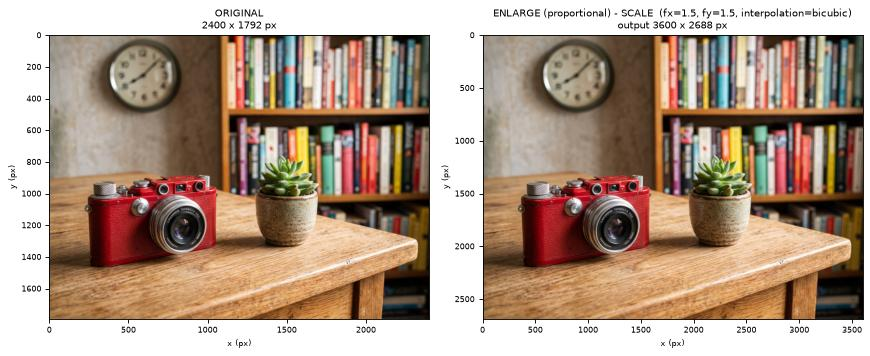

scale     fx=1.5, fy=1.5, interpolation=bicubic                   -> output 3600 x 2688 px  | saved: results\01_scale_enlarge_1.5x1.5_bicubic.jpg


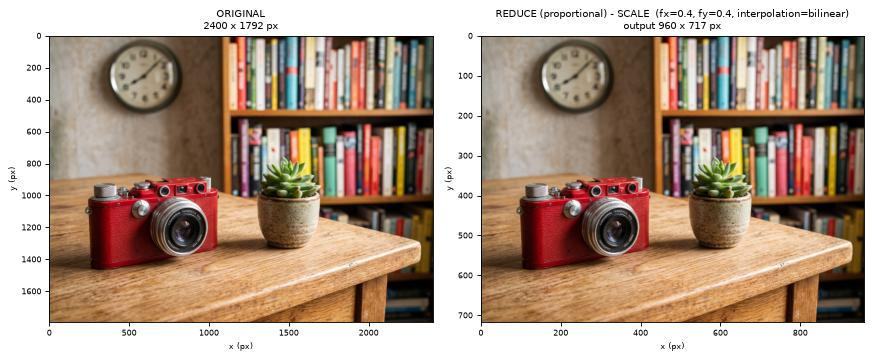

scale     fx=0.4, fy=0.4, interpolation=bilinear                  -> output 960 x 717 px  | saved: results\02_scale_reduce_0.4x0.4_bilinear.jpg


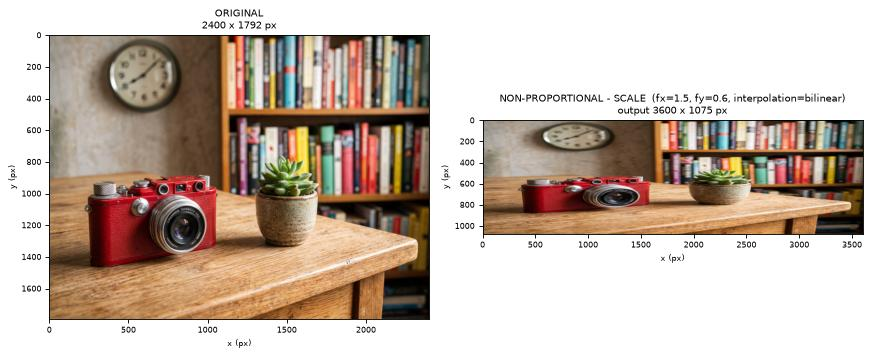

scale     fx=1.5, fy=0.6, interpolation=bilinear                  -> output 3600 x 1075 px  | saved: results\03_scale_nonproportional_1.5x0.6_bilinear.jpg


,image,width,height,aspect ratio w/h
0,original,2400,1792,1.3393
1,enlarged 1.5 x 1.5,3600,2688,1.3393
2,reduced 0.4 x 0.4,960,717,1.3389
3,non-proportional 1.5 x 0.6,3600,1075,3.3488


In [9]:
up   = run(original, "scale", "01_scale_enlarge_1.5x1.5_bicubic.jpg",  title_prefix="ENLARGE (proportional) - ",
           fx=1.5, fy=1.5, interpolation="bicubic")
down = run(original, "scale", "02_scale_reduce_0.4x0.4_bilinear.jpg",  title_prefix="REDUCE (proportional) - ",
           fx=0.4, fy=0.4, interpolation="bilinear")
nonp = run(original, "scale", "03_scale_nonproportional_1.5x0.6_bilinear.jpg", title_prefix="NON-PROPORTIONAL - ",
           fx=1.5, fy=0.6, interpolation="bilinear")

rows = []
for label, img in [("original", original), ("enlarged 1.5 x 1.5", up), ("reduced 0.4 x 0.4", down),
                   ("non-proportional 1.5 x 0.6", nonp)]:
    h, w = img.shape[:2]
    rows.append({"image": label, "width": w, "height": h, "aspect ratio w/h": round(w / h, 4)})
display(pd.DataFrame(rows))

### 5.2 Cropping

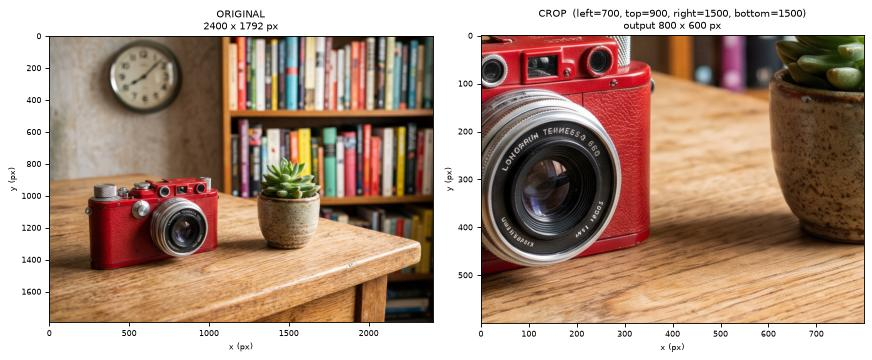

crop      left=700, top=900, right=1500, bottom=1500              -> output 800 x 600 px  | saved: results\04_crop_left700_top900_right1500_bottom1500.jpg
Cropped array shape = (600, 800, 3)  (= bottom-top, right-left, 3) = (600, 800, 3)  -> right/bottom exclusive


In [10]:
cropped = run(original, "crop", "04_crop_left700_top900_right1500_bottom1500.jpg",
              left=700, top=900, right=1500, bottom=1500)
print(f"Cropped array shape = {cropped.shape}  (= bottom-top, right-left, 3) = ({1500-900}, {1500-700}, 3)  -> right/bottom exclusive")

### 5.3 Flipping – all three directions

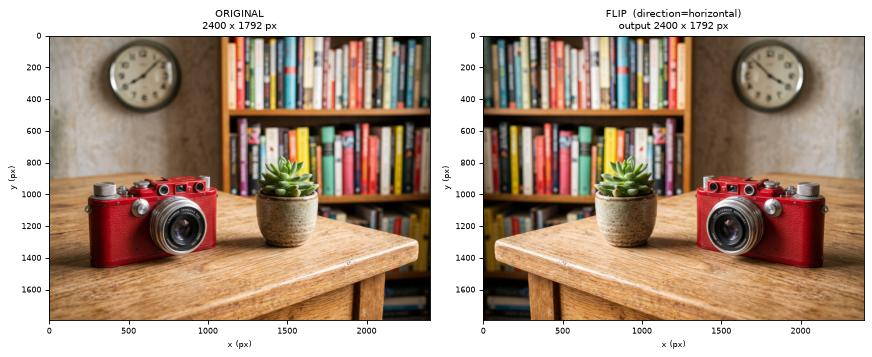

flip      direction=horizontal                                    -> output 2400 x 1792 px  | saved: results\05_flip_horizontal.jpg


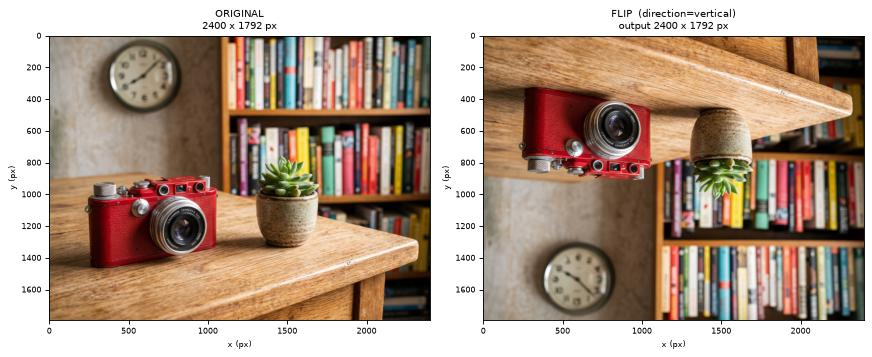

flip      direction=vertical                                      -> output 2400 x 1792 px  | saved: results\06_flip_vertical.jpg


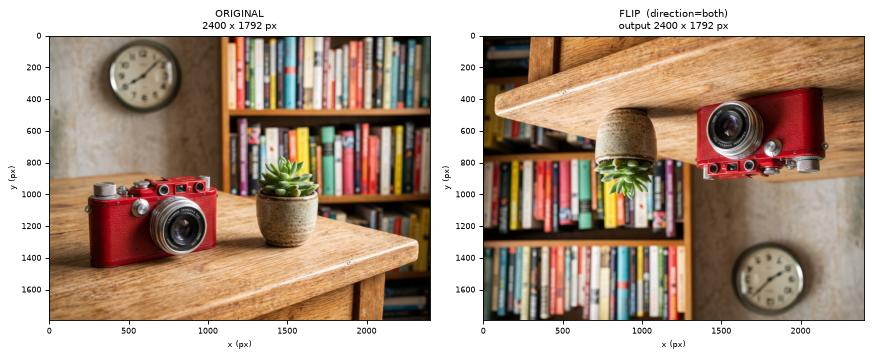

flip      direction=both                                          -> output 2400 x 1792 px  | saved: results\07_flip_both.jpg


In [11]:
flip_h = run(original, "flip", "05_flip_horizontal.jpg", direction="horizontal")
flip_v = run(original, "flip", "06_flip_vertical.jpg",   direction="vertical")
flip_b = run(original, "flip", "07_flip_both.jpg",       direction="both")

### 5.4 Translation – shifts in opposite directions

Canvas size is kept. Pixels shifted past the canvas edge are **clipped (lost)**, and the area uncovered on the opposite
side is **exposed background**, filled with black `(0, 0, 0)`. A positive `tx` moves the image right and a positive `ty` moves it down.

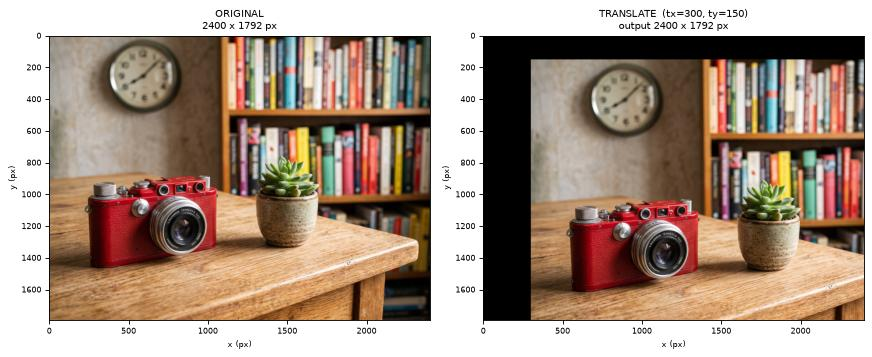

translate tx=300, ty=150                                          -> output 2400 x 1792 px  | saved: results\08_translate_tx+300_ty+150.jpg


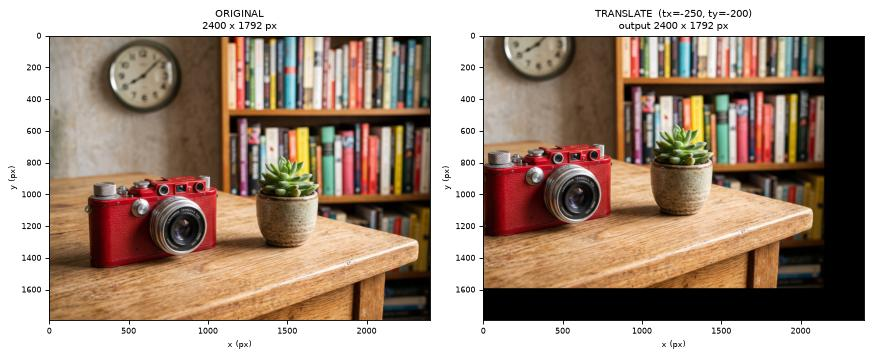

translate tx=-250, ty=-200                                        -> output 2400 x 1792 px  | saved: results\09_translate_tx-250_ty-200.jpg


,tx,ty,pixels kept,kept %,clipped (lost) %,exposed black band
0,300,150,3448200,80.2,19.8,300 px wide (x) + 150 px tall (y)
1,-250,-200,3422800,79.6,20.4,250 px wide (x) + 200 px tall (y)


In [12]:
t1 = run(original, "translate", "08_translate_tx+300_ty+150.jpg", tx=300, ty=150)     # right and down
t2 = run(original, "translate", "09_translate_tx-250_ty-200.jpg", tx=-250, ty=-200)   # left and up

# quantify clipping for the two shifts
rows = []
for tx, ty in [(300, 150), (-250, -200)]:
    kept = (W0 - abs(tx)) * (H0 - abs(ty))
    rows.append({"tx": tx, "ty": ty,
                 "pixels kept": kept, "kept %": round(100 * kept / (W0 * H0), 1),
                 "clipped (lost) %": round(100 * (1 - kept / (W0 * H0)), 1),
                 "exposed black band": f"{abs(tx)} px wide (x) + {abs(ty)} px tall (y)"})
display(pd.DataFrame(rows))

### 5.5 Rotation – positive and negative angles, with and without canvas expansion

Rotation is about the **image centre**. A **positive angle rotates counter-clockwise** as displayed; a negative angle rotates clockwise.
With `expand=False` the canvas stays the same size and the corners are clipped; with `expand=True` the canvas grows to
`w' = w|cos θ| + h|sin θ|`, `h' = w|sin θ| + h|cos θ|` so nothing is cut off.

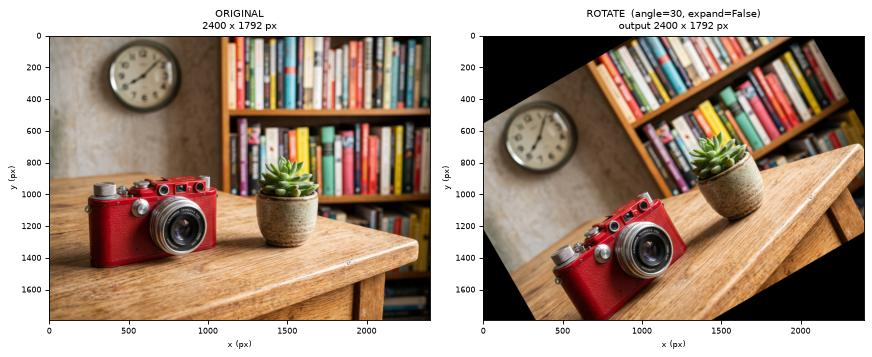

rotate    angle=30, expand=False                                  -> output 2400 x 1792 px  | saved: results\10_rotate_+30_expand_False.jpg


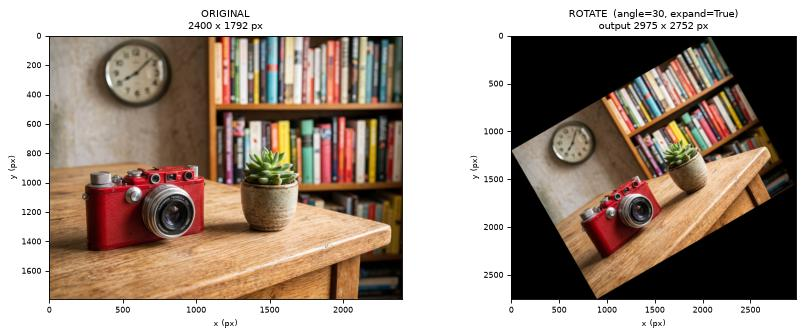

rotate    angle=30, expand=True                                   -> output 2975 x 2752 px  | saved: results\11_rotate_+30_expand_True.jpg


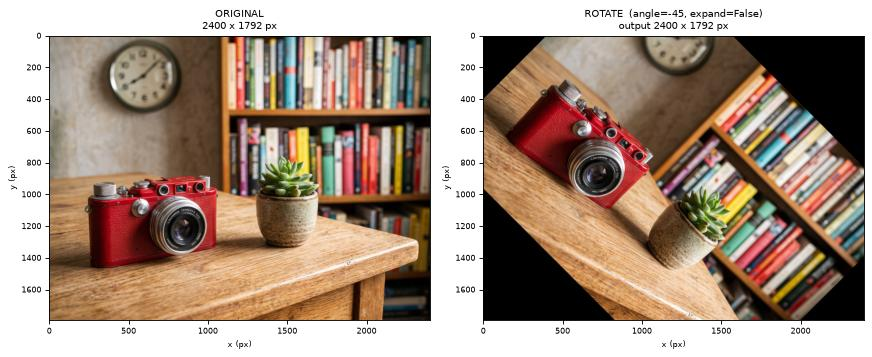

rotate    angle=-45, expand=False                                 -> output 2400 x 1792 px  | saved: results\12_rotate_-45_expand_False.jpg


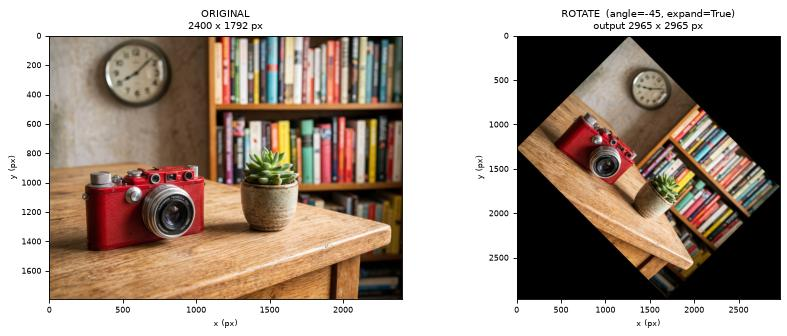

rotate    angle=-45, expand=True                                  -> output 2965 x 2965 px  | saved: results\13_rotate_-45_expand_True.jpg


,angle,formula w' x h',actual,match
0,30,2975 x 2752,2975 x 2752,True
1,-45,2965 x 2965,2965 x 2965,True


In [13]:
r1 = run(original, "rotate", "10_rotate_+30_expand_False.jpg", angle=30,  expand=False)
r2 = run(original, "rotate", "11_rotate_+30_expand_True.jpg",  angle=30,  expand=True)
r3 = run(original, "rotate", "12_rotate_-45_expand_False.jpg", angle=-45, expand=False)
r4 = run(original, "rotate", "13_rotate_-45_expand_True.jpg",  angle=-45, expand=True)

# check the expanded sizes against the formula
rows = []
for ang, img in [(30, r2), (-45, r4)]:
    t = math.radians(ang)
    ew = math.ceil(round(W0 * abs(math.cos(t)) + H0 * abs(math.sin(t)), 6))
    eh = math.ceil(round(W0 * abs(math.sin(t)) + H0 * abs(math.cos(t)), 6))
    rows.append({"angle": ang, "formula w' x h'": f"{ew} x {eh}", "actual": f"{img.shape[1]} x {img.shape[0]}",
                 "match": (ew, eh) == (img.shape[1], img.shape[0])})
display(pd.DataFrame(rows))

### 5.6 Affine matrices behind translation and rotation

Translation and rotation are **affine transformations**: every output pixel position is a linear combination of the input position plus an offset,
`[x', y']ᵀ = A · [x, y]ᵀ + [tx, ty]ᵀ`, stored as a 2 x 3 matrix `M = [A | t]` and applied with `cv2.warpAffine`.
`transform` builds `M` with `translation_matrix` and `rotation_matrix` (section 3). The cell below prints the matrices for the demonstrations above and
**verifies** that applying `M` directly with `cv2.warpAffine` reproduces the images returned by `transform` (0 differing values).

* Translation: `A` is the identity and `t = (tx, ty)`.
* Rotation about the centre by angle θ (counter-clockwise on screen): `A = [[cos θ, sin θ], [−sin θ, cos θ]]`, and `t` is chosen so the image centre stays fixed (with `expand=True` it is shifted again to the centre of the larger canvas).

In [14]:
np.set_printoptions(precision=4, suppress=True)

def verify_affine(label, result, M, size):
    direct = cv2.warpAffine(original, M, size, flags=ROTATION_INTERPOLATION,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=FILL_VALUE)
    same = direct.shape == result.shape and np.array_equal(direct, result)
    print(f"{label}\n{M}\n  warpAffine(M) vs transform() -> output {size[0]} x {size[1]}, "
          f"identical: {same}\n")
    return same

affine_ok = []
for (tx, ty), res in [((300, 150), t1), ((-250, -200), t2)]:
    affine_ok.append(verify_affine(f"translate tx={tx}, ty={ty}", res, translation_matrix(tx, ty), (W0, H0)))

for (ang, exp), res in [((30, False), r1), ((30, True), r2), ((-45, False), r3), ((-45, True), r4)]:
    M, ow, oh = rotation_matrix(W0, H0, ang, exp)
    affine_ok.append(verify_affine(f"rotate angle={ang}, expand={exp}", res, M, (ow, oh)))

print("All affine matrices reproduce the transform() outputs exactly:", all(affine_ok))

translate tx=300, ty=150
[[  1.   0. 300.]
 [  0.   1. 150.]]
  warpAffine(M) vs transform() -> output 2400 x 1792, identical: True

translate tx=-250, ty=-200
[[   1.    0. -250.]
 [   0.    1. -200.]]
  warpAffine(M) vs transform() -> output 2400 x 1792, identical: True

rotate angle=30, expand=False
[[   0.866     0.5    -287.0475]
 [  -0.5       0.866   719.7243]]
  warpAffine(M) vs transform() -> output 2400 x 1792, identical: True

rotate angle=30, expand=True
[[   0.866     0.5       0.4525]
 [  -0.5       0.866  1199.7243]]
  warpAffine(M) vs transform() -> output 2975 x 2752, identical: True

rotate angle=-45, expand=False
[[   0.7071   -0.7071  984.5395]
 [   0.7071    0.7071 -585.8887]]
  warpAffine(M) vs transform() -> output 2400 x 1792, identical: True

rotate angle=-45, expand=True
[[   0.7071   -0.7071 1267.0395]
 [   0.7071    0.7071    0.6113]]
  warpAffine(M) vs transform() -> output 2965 x 2965, identical: True

All affine matrices reproduce the transform() outputs 

## 6. Interpolation comparison on the same enlarged patch

A small patch (a screw head and the edge of the silver lens ring) is cropped with `transform`, then enlarged **6x** with each
interpolation method through the same `transform` function. The patch is deliberately detailed (a screw head and a sharp
red-to-silver ring edge), so differences are easy to see. The table reports the variance of the Laplacian as a rough edge-strength measure; it counts hard block edges as edges, so it is interpreted with care below.

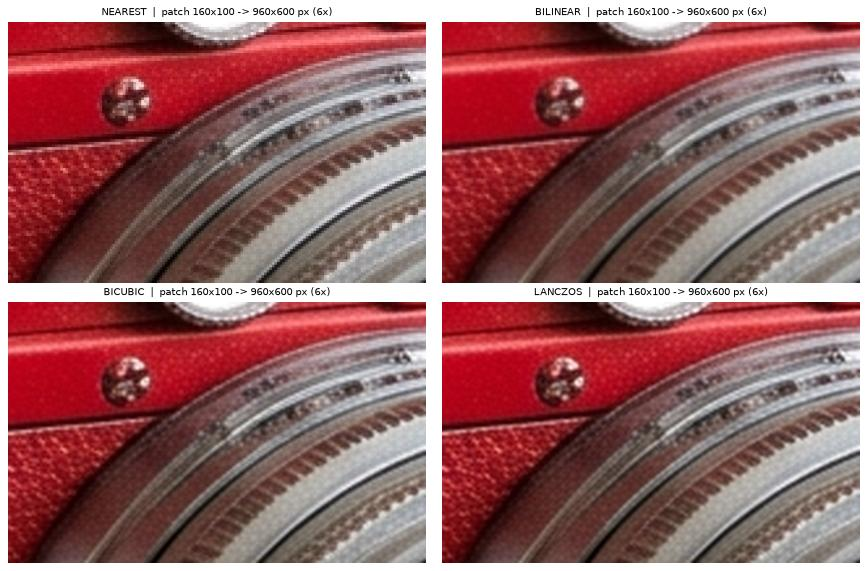

,method,output size,Laplacian variance (edge strength)
0,nearest,960 x 600,341.6
1,bilinear,960 x 600,5.7
2,bicubic,960 x 600,5.4
3,lanczos,960 x 600,5.4


In [15]:
patch = transform(original, "crop", left=640, top=1000, right=800, bottom=1100)       # 160 x 100 px patch
save_image(os.path.join(RESULTS_DIR, "14_interp_patch_original.png"), patch)

enlarged = {}
for name in INTERPOLATIONS:
    enlarged[name] = transform(patch, "scale", fx=6, fy=6, interpolation=name)
    save_image(os.path.join(RESULTS_DIR, f"15_interp_patch_x6_{name}.png"), enlarged[name])

fig, axes = plt.subplots(2, 2, figsize=(11, 7.2))
for ax, (name, img) in zip(axes.ravel(), enlarged.items()):
    ax.imshow(img)
    ax.set_title(f"{name.upper()}  |  patch {patch.shape[1]}x{patch.shape[0]} -> {img.shape[1]}x{img.shape[0]} px (6x)", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

def sharpness(img):
    return cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()

display(pd.DataFrame([{"method": n, "output size": f"{i.shape[1]} x {i.shape[0]}",
                       "Laplacian variance (edge strength)": round(sharpness(i), 1)} for n, i in enlarged.items()]))

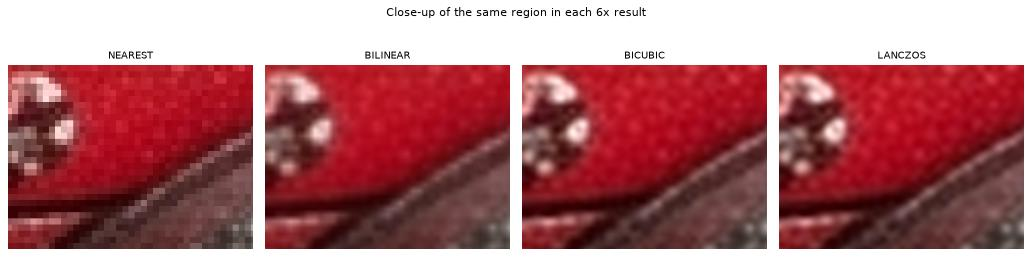

In [16]:
# Zoom further on a small region so pixel-level differences are clearly visible
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, img) in zip(axes, enlarged.items()):
    zoom = img[120:300, 260:500]
    ax.imshow(zoom); ax.set_title(name.upper(), fontsize=9); ax.axis("off")
plt.suptitle("Close-up of the same region in each 6x result", fontsize=10)
plt.tight_layout(); plt.show()

**Cost of each method.** The table above times the same 6x enlargement for each method (best of 30 runs) so the cost claim in the observations below is *measured on this machine* instead of assumed. Absolute times depend on the computer; the ranking is what matters.

In [17]:
import time

def best_time_ms(interp, repeats=30):
    '''Best-of-N wall-clock time (ms) of one 6x enlargement of the patch through transform().'''
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        transform(patch, "scale", fx=6, fy=6, interpolation=interp)
        best = min(best, time.perf_counter() - t0)
    return best * 1000

timing_df = pd.DataFrame([{"method": n, "kernel (source pixels used per output pixel)": k,
                           "best time for 160x100 -> 960x600 (ms)": round(best_time_ms(n), 2)}
                          for n, k in [("nearest", "1 (1 x 1)"), ("bilinear", "4 (2 x 2)"),
                                       ("bicubic", "16 (4 x 4)"), ("lanczos", "64 (8 x 8)")]])
display(timing_df)

,method,kernel (source pixels used per output pixel),best time for 160x100 -> 960x600 (ms)
0,nearest,1 (1 x 1),1.06
1,bilinear,4 (2 x 2),1.04
2,bicubic,16 (4 x 4),1.81
3,lanczos,64 (8 x 8),4.45


**Observations (interpolation)**, based on the 6x results and the close-ups above:

- **Nearest-neighbour** copies the closest source pixel, so every source pixel becomes a visible 6 x 6 block. Edges are staircased and the screw head and the ridge of the lens ring look jagged and blocky. It invents no new colours and does the least arithmetic per pixel.
- **Bilinear** averages the 4 nearest pixels. The blockiness is gone and edges are smooth, but this is the softest result: the screw and the thin bright ridge look blurred.
- **Bicubic** uses a 4 x 4 neighbourhood. It is smooth like bilinear but keeps edges and the screw outline visibly crisper.
- **Lanczos** uses an 8 x 8 neighbourhood. It looks very close to bicubic; the difference is subtle, with slightly more contrast on the thin bright ridge and the screw highlights. Its larger kernel makes it the most expensive method per output pixel; the timing table above gives the measured cost.

About the table: the Laplacian variance of nearest (about 342) is far higher than the other three (about 5 to 6) only because the hard block boundaries are strong artificial edges, so the number must **not** be read as "more real detail". Among the three smooth methods the metric cannot separate them (bilinear at 5.7 is even marginally above bicubic and Lanczos at 5.4), so I rely on visual inspection for those three; the visual comparison is the more reliable evidence here.

## 7. Rejected inputs – at least one per operation

`expect_rejection` calls `transform` with an invalid input and records the error message. A case passes only if
`ValidationError` is raised (no unhandled crash, no silent default). Several cases per operation are shown, plus
general failures (unknown operation, missing or extra parameters, bad image).

In [18]:
rejection_log = []

def expect_rejection(operation_label, case, image, operation, **params):
    try:
        transform(image, operation, **params)
        rejection_log.append({"operation": operation_label, "invalid input": case,
                              "result": "NOT REJECTED (FAIL)", "message": ""})
    except ValidationError as e:
        rejection_log.append({"operation": operation_label, "invalid input": case,
                              "result": "Rejected (PASS)", "message": str(e)})

# ---------------- scaling
expect_rejection("scale", "fx = 0",                         original, "scale", fx=0, fy=1, interpolation="bilinear")
expect_rejection("scale", "fy = -2 (negative)",             original, "scale", fx=1, fy=-2, interpolation="bilinear")
expect_rejection("scale", "fx = NaN",                       original, "scale", fx=float("nan"), fy=1, interpolation="bilinear")
expect_rejection("scale", "fy = infinity",                  original, "scale", fx=1, fy=float("inf"), interpolation="bilinear")
expect_rejection("scale", "fx = 'abc' (non-numeric)",       original, "scale", fx="abc", fy=1, interpolation="bilinear")
expect_rejection("scale", "unsupported interpolation 'sinc'", original, "scale", fx=1, fy=1, interpolation="sinc")
expect_rejection("scale", "empty output (fx = 0.0001 -> width 0)", original, "scale", fx=0.0001, fy=1, interpolation="nearest")
expect_rejection("scale", "output too large (fx = fy = 5)", original, "scale", fx=5, fy=5, interpolation="nearest")
expect_rejection("scale", "missing parameter (no interpolation)", original, "scale", fx=1, fy=1)
# ---------------- cropping
expect_rejection("crop", "right <= left (600 <= 800)",      original, "crop", left=800, top=0, right=600, bottom=500)
expect_rejection("crop", "right beyond width",              original, "crop", left=0, top=0, right=W0 + 1, bottom=100)
expect_rejection("crop", "negative left",                   original, "crop", left=-1, top=0, right=100, bottom=100)
expect_rejection("crop", "bottom <= top (empty region)",    original, "crop", left=0, top=100, right=100, bottom=100)
expect_rejection("crop", "non-integer coordinate 10.5",     original, "crop", left=10.5, top=0, right=100, bottom=100)
# ---------------- flipping
expect_rejection("flip", "unsupported direction 'diagonal'", original, "flip", direction="diagonal")
expect_rejection("flip", "direction = None",                original, "flip", direction=None)
# ---------------- translation
expect_rejection("translate", "tx = NaN",                   original, "translate", tx=float("nan"), ty=0)
expect_rejection("translate", "ty = -infinity",             original, "translate", tx=0, ty=float("-inf"))
expect_rejection("translate", "tx = 'ten' (non-numeric)",   original, "translate", tx="ten", ty=0)
expect_rejection("translate", "missing ty",                 original, "translate", tx=5)
# ---------------- rotation
expect_rejection("rotate", "angle = 'ninety' (non-numeric)", original, "rotate", angle="ninety", expand=True)
expect_rejection("rotate", "angle = NaN",                   original, "rotate", angle=float("nan"), expand=True)
expect_rejection("rotate", "angle = infinity",              original, "rotate", angle=float("inf"), expand=False)
expect_rejection("rotate", "expand = 'maybe'",              original, "rotate", angle=10, expand="maybe")
expect_rejection("rotate", "missing expand",                original, "rotate", angle=10)
# ---------------- general
expect_rejection("general", "unknown operation 'blur'",     original, "blur", radius=3)
expect_rejection("general", "operation = 5 (not a string)", original, 5)
expect_rejection("general", "unexpected extra parameter",   original, "flip", direction="both", speed=3)
expect_rejection("general", "image is None",                None, "flip", direction="both")
expect_rejection("general", "empty image array",            np.zeros((0, 10, 3), np.uint8), "flip", direction="both")

rej = pd.DataFrame(rejection_log)
display(rej)
print(f"{(rej['result'] == 'Rejected (PASS)').sum()} of {len(rej)} invalid inputs were correctly rejected with a clear message "
      f"(and no unhandled crash).")

,operation,invalid input,result,message
0,scale,fx = 0,Rejected (PASS),"scale factors must be greater than zero, got fx=0.0, fy=1.0."
1,scale,fy = -2 (negative),Rejected (PASS),"scale factors must be greater than zero, got fx=1.0, fy=-2.0."
2,scale,fx = NaN,Rejected (PASS),"'fx' must be finite (not NaN or infinity), got nan."
3,scale,fy = infinity,Rejected (PASS),"'fy' must be finite (not NaN or infinity), got inf."
4,scale,fx = 'abc' (non-numeric),Rejected (PASS),"'fx' must be a number, got 'abc' (str)."
5,scale,unsupported interpolation 'sinc',Rejected (PASS),"unsupported interpolation 'sinc'. Choose one of: nearest, bilinear, bicubic, lanczos."
6,scale,empty output (fx = 0.0001 -> width 0),Rejected (PASS),output would be 0 x 1792 px; both dimensions must be at least 1 pixel.
7,scale,output too large (fx = fy = 5),Rejected (PASS),output 12000 x 8960 px exceeds the maximum side length of 10000 px.
8,scale,missing parameter (no interpolation),Rejected (PASS),'scale' is missing required parameter(s): interpolation.
9,crop,right <= left (600 <= 800),Rejected (PASS),"horizontal crop must satisfy 0 <= left < right <= 2400; got left=800, right=600."


30 of 30 invalid inputs were correctly rejected with a clear message (and no unhandled crash).


### 7.1 Boundary and special inputs that must be **accepted**

Valid zero values, negative values and exact boundaries must not be rejected.

In [19]:
accept_rows = []
def expect_accept(label, expected_shape, operation, **params):
    try:
        out = transform(original, operation, **params)
        ok = out.shape == expected_shape
        accept_rows.append({"valid boundary input": label, "expected output shape": expected_shape,
                            "actual output shape": out.shape, "result": "Accepted (PASS)" if ok else "FAIL"})
    except ValidationError as e:
        accept_rows.append({"valid boundary input": label, "expected output shape": expected_shape,
                            "actual output shape": "-", "result": f"WRONGLY REJECTED (FAIL): {e}"})

expect_accept("crop the whole image (0, 0, W, H)",           (H0, W0, 3), "crop", left=0, top=0, right=W0, bottom=H0)
expect_accept("crop a single pixel",                         (1, 1, 3),   "crop", left=0, top=0, right=1, bottom=1)
expect_accept("translate tx = 0, ty = 0",                    (H0, W0, 3), "translate", tx=0, ty=0)
expect_accept("translate negative tx = -50, ty = -50",       (H0, W0, 3), "translate", tx=-50, ty=-50)
expect_accept("translate entirely off the canvas (tx = W)",  (H0, W0, 3), "translate", tx=W0, ty=0)
expect_accept("rotate angle = 0",                            (H0, W0, 3), "rotate", angle=0, expand=False)
expect_accept("rotate negative angle = -90, expand=False",   (H0, W0, 3), "rotate", angle=-90, expand=False)
expect_accept("rotate 90 degrees, expand=True (swaps W,H)",  (W0, H0, 3), "rotate", angle=90, expand=True)
expect_accept("rotate huge finite angle 1e9",                (H0, W0, 3), "rotate", angle=1e9, expand=False)
expect_accept("scale to the smallest valid output (1 x 1)",  (1, 1, 3),   "scale", fx=1/W0, fy=1/H0, interpolation="nearest")
expect_accept("scale 'BILINEAR ' (case/space tolerant)",     (H0 // 2, W0 // 2, 3), "scale", fx=0.5, fy=0.5, interpolation="BILINEAR ")
display(pd.DataFrame(accept_rows))

,valid boundary input,expected output shape,actual output shape,result
0,"crop the whole image (0, 0, W, H)","(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
1,crop a single pixel,"(1, 1, 3)","(1, 1, 3)",Accepted (PASS)
2,"translate tx = 0, ty = 0","(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
3,"translate negative tx = -50, ty = -50","(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
4,translate entirely off the canvas (tx = W),"(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
5,rotate angle = 0,"(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
6,"rotate negative angle = -90, expand=False","(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
7,"rotate 90 degrees, expand=True (swaps W,H)","(2400, 1792, 3)","(2400, 1792, 3)",Accepted (PASS)
8,rotate huge finite angle 1e9,"(1792, 2400, 3)","(1792, 2400, 3)",Accepted (PASS)
9,scale to the smallest valid output (1 x 1),"(1, 1, 3)","(1, 1, 3)",Accepted (PASS)


## 8. Identity checks

Zero translation, scale factors of one and zero rotation must leave the image **exactly** unchanged. The table records the
expected behaviour, the actual behaviour (shape and number of differing pixels) and Pass / Fail. A few additional
identity-style checks are included.

In [20]:
checks = []

def identity_check(name, expected, **call):
    out = transform(original, **call)
    same_shape = out.shape == original.shape
    diff = int(np.count_nonzero(out != original)) if same_shape else -1
    ok = same_shape and diff == 0
    actual = (f"shape {out.shape}, {diff} differing values" if same_shape else f"shape changed to {out.shape}")
    checks.append({"check": name, "expected behaviour": expected, "actual behaviour": actual,
                   "Pass/Fail": "Pass" if ok else "Fail"})

expected_same = "Output identical to original (same shape, 0 differing values)"
identity_check("translate tx=0, ty=0",                 expected_same, operation="translate", tx=0, ty=0)
for m in INTERPOLATIONS:
    identity_check(f"scale fx=1, fy=1 ({m})",          expected_same, operation="scale", fx=1, fy=1, interpolation=m)
identity_check("rotate angle=0, expand=False",         expected_same, operation="rotate", angle=0, expand=False)
identity_check("rotate angle=0, expand=True",          expected_same, operation="rotate", angle=0, expand=True)
identity_check("rotate angle=360, expand=False",       expected_same, operation="rotate", angle=360, expand=False)
identity_check("crop whole image",                     expected_same, operation="crop", left=0, top=0, right=W0, bottom=H0)

# flipping twice returns the original
twice = transform(transform(original, "flip", direction="horizontal"), "flip", direction="horizontal")
checks.append({"check": "flip horizontal applied twice", "expected behaviour": expected_same,
               "actual behaviour": f"{int(np.count_nonzero(twice != original))} differing values",
               "Pass/Fail": "Pass" if np.array_equal(twice, original) else "Fail"})

# rotate +90 then -90 (expand=True) returns the original
back = transform(transform(original, "rotate", angle=90, expand=True), "rotate", angle=-90, expand=True)
ok = back.shape == original.shape and int(np.abs(back.astype(int) - original.astype(int)).max()) <= 1
checks.append({"check": "rotate +90 then -90 (expand=True)", "expected behaviour": "Same shape; values equal within +/-1 (resampling rounding)",
               "actual behaviour": f"shape {back.shape}, max abs difference {int(np.abs(back.astype(int) - original.astype(int)).max())}",
               "Pass/Fail": "Pass" if ok else "Fail"})

check_df = pd.DataFrame(checks)
display(check_df)
print(f"{(check_df['Pass/Fail'] == 'Pass').sum()} of {len(check_df)} checks passed.")

,check,expected behaviour,actual behaviour,Pass/Fail
0,"translate tx=0, ty=0","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
1,"scale fx=1, fy=1 (nearest)","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
2,"scale fx=1, fy=1 (bilinear)","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
3,"scale fx=1, fy=1 (bicubic)","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
4,"scale fx=1, fy=1 (lanczos)","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
5,"rotate angle=0, expand=False","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
6,"rotate angle=0, expand=True","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
7,"rotate angle=360, expand=False","Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
8,crop whole image,"Output identical to original (same shape, 0 differing values)","shape (1792, 2400, 3), 0 differing values",Pass
9,flip horizontal applied twice,"Output identical to original (same shape, 0 differing values)",0 differing values,Pass


11 of 11 checks passed.


## 9. Observations

### 9.1 Image coordinates versus array indexing

In [21]:
x, y = 700, 900                                  # a point in IMAGE coordinates: x to the right, y downwards
print(f"Image coordinate (x={x}, y={y})  ->  array element original[{y}, {x}]  (row = y, column = x)")
print("pixel value (R, G, B):", original[y, x])
print(f"original.shape = {original.shape} = (height, width, channels) = ({H0}, {W0}, 3)")
print(f"but the size in image terms is width x height = {W0} x {H0}")

# demonstrate with cv2.resize, which takes (width, height), while shape gives (height, width)
demo = cv2.resize(original, (W0 // 4, H0 // 2))
print(f"cv2.resize(original, (W0//4, H0//2)) -> dsize=(width={W0//4}, height={H0//2}) -> demo.shape = {demo.shape}")

Image coordinate (x=700, y=900)  ->  array element original[900, 700]  (row = y, column = x)
pixel value (R, G, B): [194 146  97]
original.shape = (1792, 2400, 3) = (height, width, channels) = (1792, 2400, 3)
but the size in image terms is width x height = 2400 x 1792
cv2.resize(original, (W0//4, H0//2)) -> dsize=(width=600, height=896) -> demo.shape = (896, 600, 3)


- **Image coordinates** are written `(x, y)`: `x` is the column counted from the left and `y` is the row counted **downwards** from the top, with the origin `(0, 0)` at the top-left pixel.
- **NumPy indexing** is `array[row, column] = array[y, x]`: the order is swapped. `array.shape` is `(height, width, channels)`, while sizes in OpenCV calls such as `cv2.resize(img, (width, height))` and `cv2.warpAffine(..., (width, height))` are given as `(width, height)`.
- Mixing the two orders is a classic bug: for example, cropping is `img[top:bottom, left:right]` (rows first), and the y-axis points down, so a *positive* `ty` moves content down.
- Crop limits are half-open: `right` and `bottom` are **exclusive**, so the crop shape is `(bottom − top, right − left)` and `right = width` / `bottom = height` is valid.

### 9.2 Aspect-ratio distortion

In [22]:
for label, img in [("original", original), ("proportional 1.5 x 1.5", up), ("proportional 0.4 x 0.4", down),
                   ("non-proportional 1.5 x 0.6", nonp)]:
    h, w = img.shape[:2]
    print(f"{label:28} {w:5d} x {h:5d}   aspect ratio w/h = {w/h:.3f}")
print(f"\nNon-proportional scaling multiplies the aspect ratio by fx/fy = 1.5/0.6 = {1.5/0.6:.2f}: "
      f"circles become ellipses (the clock looks wider than it should be).")

original                      2400 x  1792   aspect ratio w/h = 1.339
proportional 1.5 x 1.5        3600 x  2688   aspect ratio w/h = 1.339
proportional 0.4 x 0.4         960 x   717   aspect ratio w/h = 1.339
non-proportional 1.5 x 0.6    3600 x  1075   aspect ratio w/h = 3.349

Non-proportional scaling multiplies the aspect ratio by fx/fy = 1.5/0.6 = 2.50: circles become ellipses (the clock looks wider than it should be).


Equal factors (`fx == fy`) preserve the width-to-height ratio, so shapes keep their proportions. When `fx ≠ fy` the ratio changes by `fx / fy`: the image is stretched along one axis only, so the round clock becomes an ellipse and the plant pot is distorted (see section 5.1). That is correct behaviour for non-proportional scaling, but it should be used knowingly.

### 9.3 Rotation canvas expansion

In [23]:
for ang in (0, 30, 45, 90, -45):
    t = math.radians(ang)
    ew = math.ceil(round(W0 * abs(math.cos(t)) + H0 * abs(math.sin(t)), 6))
    eh = math.ceil(round(W0 * abs(math.sin(t)) + H0 * abs(math.cos(t)), 6))
    print(f"angle {ang:4d} deg : expand=False keeps {W0} x {H0}   |   expand=True canvas {ew} x {eh}")

angle    0 deg : expand=False keeps 2400 x 1792   |   expand=True canvas 2400 x 1792
angle   30 deg : expand=False keeps 2400 x 1792   |   expand=True canvas 2975 x 2752
angle   45 deg : expand=False keeps 2400 x 1792   |   expand=True canvas 2965 x 2965
angle   90 deg : expand=False keeps 2400 x 1792   |   expand=True canvas 1792 x 2400
angle  -45 deg : expand=False keeps 2400 x 1792   |   expand=True canvas 2965 x 2965


With `expand=False` the output keeps the original canvas size, so the rotated image's corners fall outside the canvas and are **clipped**, while triangular regions of **black background** appear (section 5.5, `+30°` and `−45°`, `expand=False`). With `expand=True` the canvas is enlarged to the bounding box of the rotated rectangle, `w' = w|cos θ| + h|sin θ|`, `h' = w|sin θ| + h|cos θ|`, so **no pixel is lost**, at the cost of a larger image and more black background. At exactly 90° the width and height are swapped, and at 0° the size is unchanged. Rotation is about the image centre and **positive angles are counter-clockwise** (as displayed).

### 9.4 Translation clipping

In [24]:
for tx, ty in [(300, 150), (-250, -200)]:
    out = transform(original, "translate", tx=tx, ty=ty)
    black_cols = out[:, :abs(tx)] if tx > 0 else out[:, W0 - abs(tx):]
    black_rows = out[:abs(ty), :] if ty > 0 else out[H0 - abs(ty):, :]
    print(f"tx={tx:5d}, ty={ty:5d}: output stays {out.shape[1]} x {out.shape[0]}; "
          f"exposed side band all black: {not black_cols.any()} ; exposed top/bottom band all black: {not black_rows.any()}")

tx=  300, ty=  150: output stays 2400 x 1792; exposed side band all black: True ; exposed top/bottom band all black: True
tx= -250, ty= -200: output stays 2400 x 1792; exposed side band all black: True ; exposed top/bottom band all black: True


Translation keeps the **original canvas size**. Shifting by `(tx, ty)` pushes part of the image past the canvas edge, and those pixels are **clipped (permanently lost)**. Shifting back later cannot restore them. On the opposite edges a band `|tx|` pixels wide and `|ty|` pixels tall is **exposed** and filled with black `(0, 0, 0)`, the declared background. For example, with `tx = 300, ty = 150` only `(W − 300)(H − 150) / (W·H)` of the original pixels remain visible (section 5.4). A shift that is at least as large as the width or height removes the whole image and leaves a black canvas.

## 10. Final integrity check and list of saved results

In [25]:
final_hash = hashlib.sha256(original.tobytes()).hexdigest()
print("Original still unchanged :", final_hash == ORIGINAL_HASH)
print("Original array writeable  :", original.flags.writeable)
assert final_hash == ORIGINAL_HASH, "The original image was modified!"

files = sorted(os.listdir(RESULTS_DIR))
print(f"\n{len(files)} saved result files in '{RESULTS_DIR}/':")
for f in files:
    im = cv2.imread(os.path.join(RESULTS_DIR, f))
    print(f"  {f:55} {im.shape[1]:5d} x {im.shape[0]:5d} px")

Original still unchanged : True
Original array writeable  : False

23 saved result files in 'results/':
  01_scale_enlarge_1.5x1.5_bicubic.jpg                     3600 x  2688 px
  02_scale_reduce_0.4x0.4_bilinear.jpg                      960 x   717 px
  03_scale_nonproportional_1.5x0.6_bilinear.jpg            3600 x  1075 px
  04_crop_left700_top900_right1500_bottom1500.jpg           800 x   600 px
  05_flip_horizontal.jpg                                   2400 x  1792 px
  06_flip_vertical.jpg                                     2400 x  1792 px
  07_flip_both.jpg                                         2400 x  1792 px
  08_translate_tx+300_ty+150.jpg                           2400 x  1792 px
  09_translate_tx-250_ty-200.jpg                           2400 x  1792 px
  10_rotate_+30_expand_False.jpg                           2400 x  1792 px
  11_rotate_+30_expand_True.jpg                            2975 x  2752 px
  12_rotate_-45_expand_False.jpg                           2400 x  1792